# 02 · SQL analysis: Paris apartment prices 2021–2025

Each section answers one business question. The SQL lives in `sql/03_analysis.sql` and is run by `src/build_database.py`, which stores each answer as an `agg_*` table and exports it to `data/processed/` for Power BI.
This notebook reads those tables, charts them, and writes one insight per question.

> Run `python src/build_database.py` first. Data: 140k cleaned apartment sales (see the cleaning funnel below). All prices are **medians in € per m²**.

In [1]:
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DB_PATH = PROJECT_ROOT / "data" / "paris_dvf.duckdb"
FIG_DIR = PROJECT_ROOT / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

con = duckdb.connect(str(DB_PATH), read_only=True)

def q(sql: str):
    """Run a query and return a pandas DataFrame."""
    return con.execute(sql).df()

BLUE = "#3b6ea5"
euro = mtick.FuncFormatter(lambda x, _: f"{x:,.0f} €")
sns.set_theme(style="whitegrid")

## Cleaning funnel (from Phase 3)

In [2]:
q('SELECT * FROM cleaning_funnel ORDER BY step_order')

,step_order,step,sales_remaining,removed,pct_of_start
0,0,All sales (distinct id_mutation),207365,<NA>,100.0
1,1,Standard sales only (Vente),204461,2904,98.6
2,2,Exactly one apartment (cellar/parking allowed),149673,54788,72.2
3,3,Price present and > 0,149617,56,72.2
4,4,Surface >= 9 m2,148640,977,71.7
5,5,Valid arrondissement (1-20),148640,0,71.7
6,6,"Price per m2 >= 3,000 EUR (non-market transfers)",143311,5329,69.1
7,7,Price per m2 within 1st-99th pct of its arrond...,140425,2886,67.7


## Q1. What is the median price per m² in each arrondissement, each year?
SQL: `MEDIAN`, `QUANTILE_CONT` grouped by arrondissement and year.

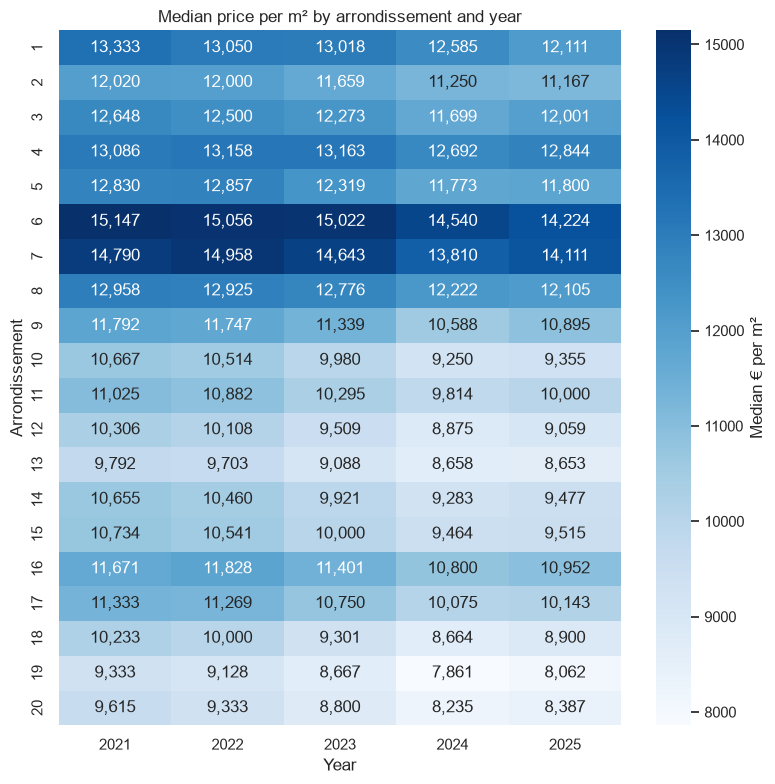

year,2021,2022,2023,2024,2025
arrondissement,,,,,
1,13333.0,13050.0,13018.0,12585.0,12111.0
2,12020.0,12000.0,11659.0,11250.0,11167.0
3,12648.0,12500.0,12273.0,11699.0,12001.0
4,13086.0,13158.0,13163.0,12692.0,12844.0
5,12830.0,12857.0,12319.0,11773.0,11800.0
6,15147.0,15056.0,15022.0,14540.0,14224.0
7,14790.0,14958.0,14643.0,13810.0,14111.0
8,12958.0,12925.0,12776.0,12222.0,12105.0
9,11792.0,11747.0,11339.0,10588.0,10895.0


In [3]:
q1 = q("SELECT * FROM agg_median_by_arr_year")
heat = q1.pivot(index="arrondissement", columns="year", values="median_price_m2")

fig, ax = plt.subplots(figsize=(8, 8))
sns.heatmap(heat, annot=True, fmt=",.0f", cmap="Blues", cbar_kws={"label": "Median € per m²"}, ax=ax)
ax.set_title("Median price per m² by arrondissement and year")
ax.set_xlabel("Year"); ax.set_ylabel("Arrondissement")
fig.tight_layout(); fig.savefig(FIG_DIR / "q1_median_by_arr_year.png", dpi=150); plt.show()
heat

**Insight:** _to be written from the real output above._

## Q2. How have prices moved year over year?
SQL: `LAG` over a window partitioned by arrondissement.

In [4]:
paris = q("SELECT * FROM agg_paris_by_year")
paris

,year,sales,median_price_m2,yoy_change_pct
0,2021,29814,10897.0,NaN
1,2022,32520,10769.0,-1.2
2,2023,26352,10225.0,-5.1
3,2024,23943,9659.0,-5.5
4,2025,27796,9774.0,1.2


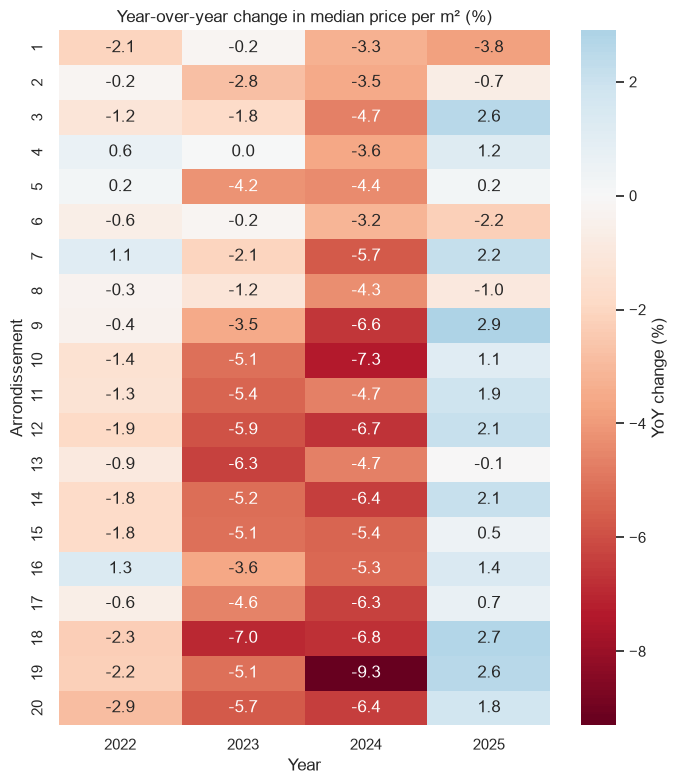

In [5]:
yoy = q("SELECT * FROM agg_yoy_change WHERE yoy_change_pct IS NOT NULL")
yoy_heat = yoy.pivot(index="arrondissement", columns="year", values="yoy_change_pct")

fig, ax = plt.subplots(figsize=(7, 8))
sns.heatmap(yoy_heat, annot=True, fmt=".1f", cmap="RdBu", center=0, cbar_kws={"label": "YoY change (%)"}, ax=ax)
ax.set_title("Year-over-year change in median price per m² (%)")
ax.set_xlabel("Year"); ax.set_ylabel("Arrondissement")
fig.tight_layout(); fig.savefig(FIG_DIR / "q2_yoy_change.png", dpi=150); plt.show()

**Insight:** _to be written from the real output above._

## Q3. Which arrondissements gained or lost the most over the period?
SQL: `FIRST_VALUE` / `LAST_VALUE` over the full window frame, then `RANK`.

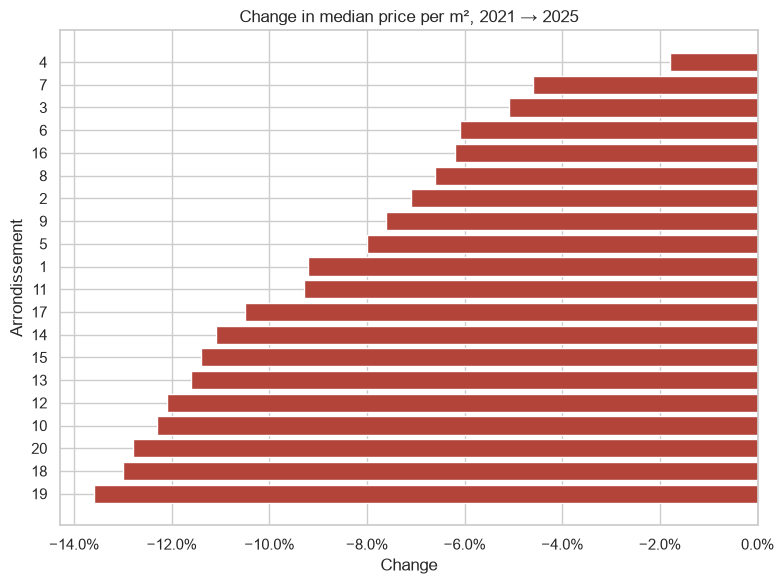

,arrondissement,first_year,last_year,first_median,last_median,change_pct,rank_gainer,rank_loser
19,4,2021,2025,13086.0,12844.0,-1.8,1,20
18,7,2021,2025,14790.0,14111.0,-4.6,2,19
17,3,2021,2025,12648.0,12001.0,-5.1,3,18
16,6,2021,2025,15147.0,14224.0,-6.1,4,17
15,16,2021,2025,11671.0,10952.0,-6.2,5,16
14,8,2021,2025,12958.0,12105.0,-6.6,6,15
13,2,2021,2025,12020.0,11167.0,-7.1,7,14
12,9,2021,2025,11792.0,10895.0,-7.6,8,13
11,5,2021,2025,12830.0,11800.0,-8.0,9,12
10,1,2021,2025,13333.0,12111.0,-9.2,10,11


In [6]:
q3 = q("SELECT * FROM agg_period_change ORDER BY change_pct")
fig, ax = plt.subplots(figsize=(8, 6))
colors = ["#b2443a" if v < 0 else BLUE for v in q3["change_pct"]]
ax.barh(q3["arrondissement"].astype(str), q3["change_pct"], color=colors)
ax.axvline(0, color="black", linewidth=0.8)
ax.xaxis.set_major_formatter(mtick.PercentFormatter())
ax.set_title(f"Change in median price per m², {q3['first_year'].min()} → {q3['last_year'].max()}")
ax.set_xlabel("Change"); ax.set_ylabel("Arrondissement")
fig.tight_layout(); fig.savefig(FIG_DIR / "q3_period_change.png", dpi=150); plt.show()
q3.sort_values("rank_gainer")

**Insight:** _to be written from the real output above._

## Q4. What is the short-term trend? Rolling 3-month median
SQL: `MEDIAN(...) OVER (ORDER BY month RANGE BETWEEN INTERVAL 2 MONTH PRECEDING AND CURRENT ROW)`, computed over all sales in the window.

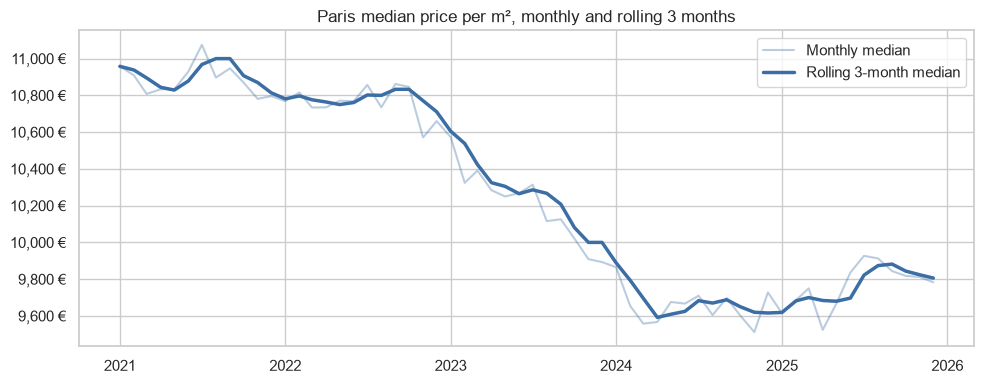

Peak:   2021-08  11,000 €/m²
Low:    2024-04  9,592 €/m²  (-12.8% vs peak)
Latest: 2025-12  9,806 €/m²


In [7]:
q4 = q("SELECT * FROM agg_rolling_3m")
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(q4["month"], q4["median_price_m2"], color=BLUE, alpha=0.35, label="Monthly median")
ax.plot(q4["month"], q4["rolling_3m_median_m2"], color=BLUE, linewidth=2.5, label="Rolling 3-month median")
ax.yaxis.set_major_formatter(euro)
ax.set_title("Paris median price per m², monthly and rolling 3 months")
ax.legend(); fig.tight_layout(); fig.savefig(FIG_DIR / "q4_rolling_3m.png", dpi=150); plt.show()

peak = q4.loc[q4["rolling_3m_median_m2"].idxmax()]
low_after_peak = q4[q4["month"] > peak["month"]].nsmallest(1, "rolling_3m_median_m2").iloc[0]
latest = q4.iloc[-1]
print(f"Peak:   {peak['month']:%Y-%m}  {peak['rolling_3m_median_m2']:,.0f} €/m²")
print(f"Low:    {low_after_peak['month']:%Y-%m}  {low_after_peak['rolling_3m_median_m2']:,.0f} €/m²  ({low_after_peak['rolling_3m_median_m2'] / peak['rolling_3m_median_m2'] - 1:+.1%} vs peak)")
print(f"Latest: {latest['month']:%Y-%m}  {latest['rolling_3m_median_m2']:,.0f} €/m²")

**Insight:** _to be written from the real output above._

## Q5. Is there seasonality in sales volume?
SQL: `DATE_TRUNC('quarter', ...)` and each quarter's share of its year.

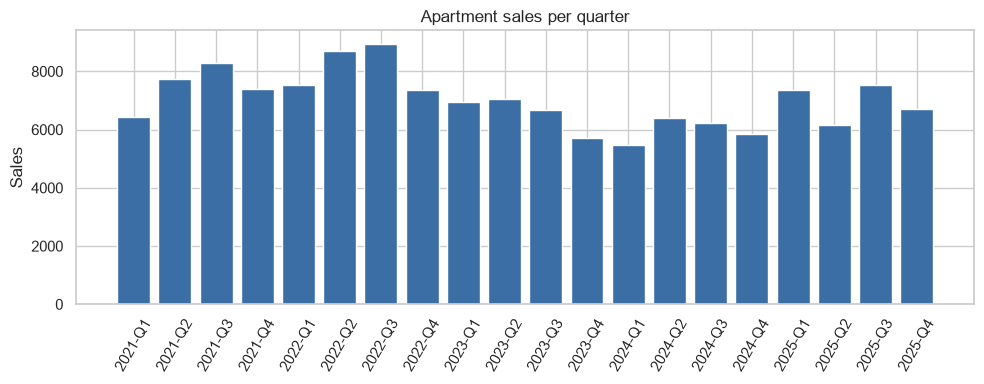

,avg_share_of_year_pct
quarter_of_year,
1,24.1
2,25.6
3,26.8
4,23.5


In [8]:
q5 = q("SELECT * FROM agg_sales_by_quarter")
fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(q5["quarter"].dt.strftime("%Y-Q") + q5["quarter_of_year"].astype(str), q5["sales"], color=BLUE)
ax.set_title("Apartment sales per quarter"); ax.set_ylabel("Sales")
plt.xticks(rotation=60); fig.tight_layout(); fig.savefig(FIG_DIR / "q5_sales_by_quarter.png", dpi=150); plt.show()

q5.groupby("quarter_of_year")["share_of_year_pct"].mean().round(1).to_frame("avg_share_of_year_pct")

**Insight:** _to be written from the real output above._

## Q6. Does price per m² depend on apartment size?
SQL: `CASE WHEN` size buckets, then `PIVOT` with one column per year.

In [9]:
q6 = q("SELECT * FROM agg_size_bucket_pivot ORDER BY size_bucket")
sizes = q("SELECT size_bucket, SUM(sales) AS sales FROM agg_size_bucket GROUP BY 1 ORDER BY 1")
q6.merge(sizes, on="size_bucket")

,size_bucket,2021,2022,2023,2024,2025,sales
0,1. < 20 m2,11313.0,11000.0,10250.0,9846.0,10000.0,14946.0
1,2. 20-35 m2,10733.0,10593.0,10000.0,9400.0,9550.0,37062.0
2,3. 35-50 m2,10560.0,10371.0,9896.0,9306.0,9457.0,30210.0
3,4. 50-80 m2,10733.0,10670.0,10100.0,9559.0,9636.0,33851.0
4,5. 80-120 m2,11389.0,11429.0,11036.0,10426.0,10389.0,16448.0
5,6. 120+ m2,12571.0,12823.0,12753.0,11979.0,12105.0,7908.0


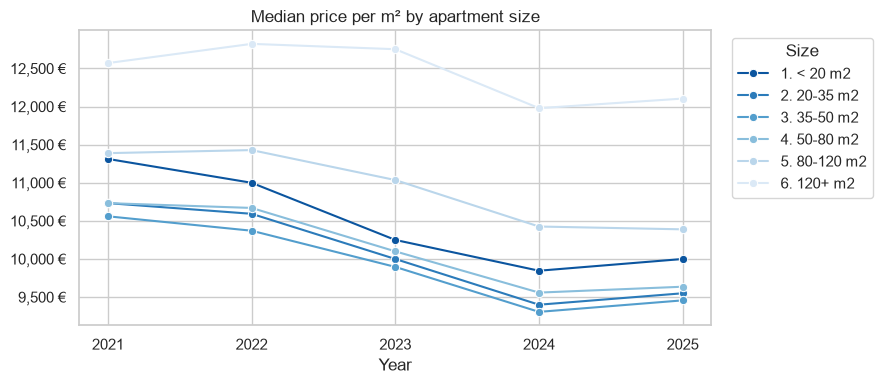

In [10]:
q6_long = q("SELECT * FROM agg_size_bucket")
fig, ax = plt.subplots(figsize=(9, 4))
sns.lineplot(data=q6_long, x="year", y="median_price_m2", hue="size_bucket", marker="o", palette="Blues_r", ax=ax)
ax.yaxis.set_major_formatter(euro); ax.set_xticks(sorted(q6_long["year"].unique()))
ax.set_title("Median price per m² by apartment size"); ax.set_xlabel("Year"); ax.set_ylabel("")
ax.legend(title="Size", bbox_to_anchor=(1.02, 1), loc="upper left")
fig.tight_layout(); fig.savefig(FIG_DIR / "q6_size_buckets.png", dpi=150); plt.show()

**Insight:** _to be written from the real output above._

## Q7. Which arrondissements have the widest price spread?
SQL: `STDDEV_SAMP` and IQR (`QUANTILE_CONT(0.75) - QUANTILE_CONT(0.25)`), with IQR as a % of the median so cheap and expensive areas are comparable.

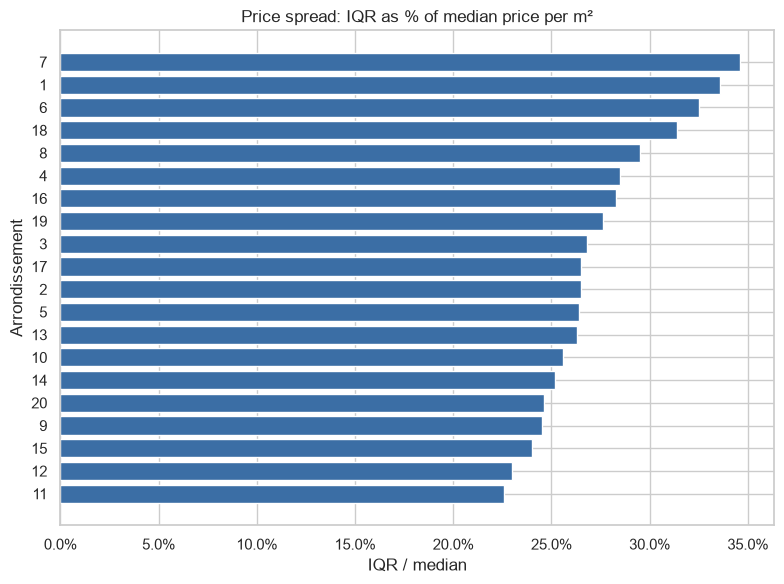

,arrondissement,sales,median_price_m2,stddev_price_m2,iqr_price_m2,iqr_pct_of_median
19,7,4214,14520.0,4688.0,5023.0,34.6
18,1,1377,12875.0,3907.0,4324.0,33.6
17,6,3614,14831.0,4577.0,4825.0,32.5
16,18,14603,9496.0,2277.0,2979.0,31.4
15,8,2943,12602.0,4236.0,3719.0,29.5
14,4,2401,13025.0,3654.0,3714.0,28.5
13,16,11498,11399.0,2864.0,3229.0,28.3
12,19,7623,8667.0,1803.0,2390.0,27.6
11,3,3086,12256.0,2880.0,3286.0,26.8
9,2,1974,11701.0,2681.0,3098.0,26.5


In [11]:
q7 = q("SELECT * FROM agg_volatility ORDER BY iqr_pct_of_median")
fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(q7["arrondissement"].astype(str), q7["iqr_pct_of_median"], color=BLUE)
ax.xaxis.set_major_formatter(mtick.PercentFormatter())
ax.set_title("Price spread: IQR as % of median price per m²"); ax.set_xlabel("IQR / median"); ax.set_ylabel("Arrondissement")
fig.tight_layout(); fig.savefig(FIG_DIR / "q7_volatility.png", dpi=150); plt.show()
q7.sort_values("iqr_pct_of_median", ascending=False)

**Insight:** _to be written from the real output above._

## Q8. Which areas are priced below what the model predicts?
_Added after Phase 6 (model)._

## Key findings

_3 to 5 findings with real numbers, written from the outputs above. These go into the README._

In [12]:
con.close()